# Comparing 5 Supervised Learning Algorithms

Dataset: Adult Census Income (OpenML). Task: predict whether income is above $50K.

Models: Logistic Regression, Decision Tree, K-Nearest Neighbors, SVM (RBF), Gaussian Naive Bayes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42

In [2]:
data = fetch_openml('adult', version=2, as_frame=True)
df = data.frame.sample(n=20000, random_state=RANDOM_STATE).reset_index(drop=True)
print(df.shape)
print(df['class'].value_counts(normalize=True))
print(df.isna().sum()[df.isna().sum() > 0])
df.head()

(20000, 15)
class
<=50K    0.7621
>50K     0.2379
Name: proportion, dtype: float64
workclass         1129
occupation        1131
native-country     350
dtype: int64


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
1,25,Private,112847,HS-grad,9,Married-civ-spouse,Transport-moving,Own-child,Other,Male,0,0,40,United-States,<=50K
2,43,Private,170525,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,14344,0,40,United-States,>50K
3,32,Private,186788,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,<=50K
4,39,Private,277886,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0,0,30,United-States,<=50K


In [3]:
y = (df['class'] == '>50K').astype(int)
X = df.drop(columns=['class'])

numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), numeric_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), categorical_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print(X_train_p.shape, X_test_p.shape)

(16000, 104) (4000, 104)


In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=15),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
}

rows = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    preds = model.predict(X_test_p)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
    })

results = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
results.index = results.index + 1
results.index.name = 'Rank'
results.round(4).to_csv('results.csv')
results.round(4)

,Model,Accuracy,Precision,Recall,F1
Rank,,,,,
1,Decision Tree,0.8505,0.7360,0.5798,0.6486
2,SVM (RBF),0.8548,0.7669,0.5599,0.6472
3,Logistic Regression,0.8498,0.7349,0.5767,0.6463
4,K-Nearest Neighbors,0.8452,0.7148,0.5819,0.6416
5,Naive Bayes,0.4060,0.2823,0.9695,0.4372


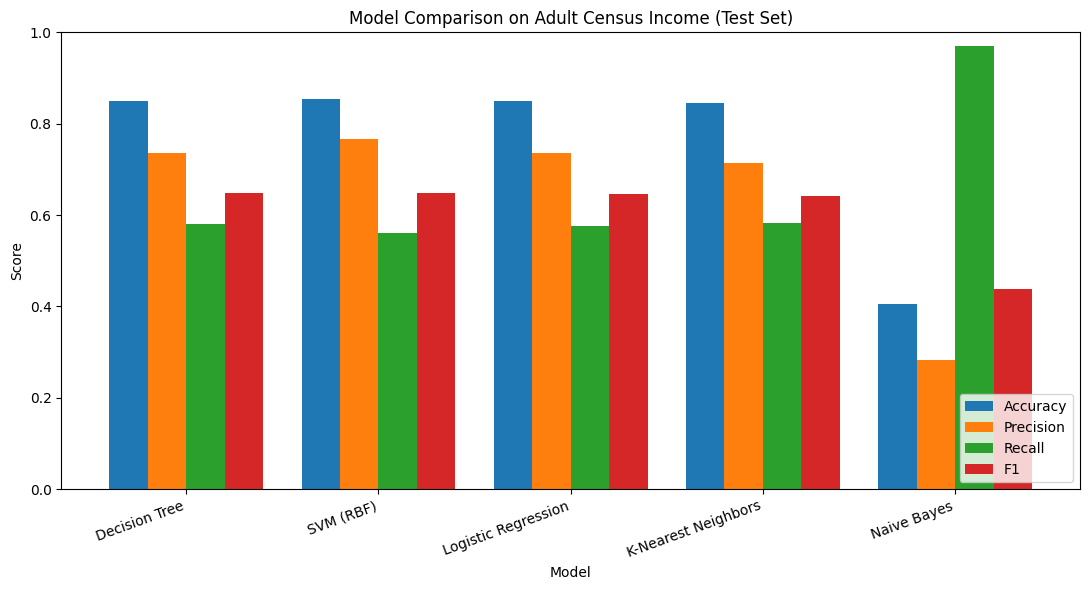

In [5]:
ax = results.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].plot(
    kind='bar', figsize=(11, 6), width=0.8
)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Model Comparison on Adult Census Income (Test Set)')
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('comparison.png', dpi=150)
plt.show()